**EEG–Eye-Tracking Multimodal Research | Presented by: Reza Saadatyar (2026)**

**02 | EEG–EyeLink Temporal Alignment and Window Quality**

![BIDS-relative EEG–EyeLink alignment and observed paired-window support](../../images/02_eeg_gaze_alignment_and_quality.svg)

**Objective:** Locate common recording intervals between original EEG and EyeLink streams, then construct comparable **non-overlapping 12-second windows** for NR and TSR.

**Method:** Use the sampling frequencies and EyeLink `StartTime` recorded in BIDS sidecars. Retain at most **20 windows per participant/task run** when at least **60%** of gaze x/y coordinates are finite.

**Observed cohort:** All **36 original runs from 18 people** contributed at least one paired window. The study retained **630/630 candidate windows**: **341 NR and 289 TSR**, distributed as **371 Train / 99 Validation / 160 reserved Test**. Every window passed the finite-coordinate criterion.

**Scope:** The retained windows meet the BIDS-relative overlap and finite-coordinate criteria. Independent clock drift and gaze calibration remain unverified, and different run lengths produce unequal window counts per participant.

**00. Colab Repository Setup**

In [ ]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
import subprocess

repo_url = "https://github.com/RezaSaadatyar/Eye-Tracking-Neurocognitive-Intelligence.git"
repo_path = Path("/content") / repo_url.rsplit("/", 1)[-1].removesuffix(".git")

if not repo_path.exists():
    subprocess.run(
        ["git", "clone", "-q", repo_url, str(repo_path)], check=True
    )

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}


/content/Eye-Tracking-Neurocognitive-Intelligence


**01. Imports and Research Environment**

In [2]:
# =================== 01. Imports and Research Environment ====================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("eeg_eye_tracking_fusion")

# ---------------------------- 2. Standard Library ----------------------------
import importlib.util
import json
import random
import shutil
import sys

# ---------------------- 3. Colab Dependency Preparation ----------------------
if importlib.util.find_spec("mne") is None:
    subprocess.run(
        [sys.executable, "-m", "pip", "-q", "install",
         "mne>=1.6,<2"],
        check=True,
    )

# ----------------- 4. Scientific Computing and Data Analysis -----------------
import numpy as np
import pandas as pd

# ------------------- 5. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style

# ----------------- 6. Shared and Project Research Utilities ------------------
from core.output_download import download_outputs_from_colab
from zuco_io import open_run, session
from alignment import (
    window_registry, ensure_disjoint_registry, eye_sample_times,
    temporal_overlap,
)

# ---------------------------- 7. Reproducibility -----------------------------
SEED = 17
random.seed(SEED)
np.random.seed(SEED)

# ------------------- 8. Output Directory and Setup Summary -------------------
work = root / "eeg_eye_tracking_fusion"
output_dir = work / "output"
output_dir.mkdir(parents=True, exist_ok=True)
raw_dir = Path("/content/zuco2_source_cache")
raw_dir.mkdir(parents=True, exist_ok=True)
plot_style(font_family="DejaVu Sans", figure_dpi=100)
print("Project outputs:", output_dir)
print("Temporary source cache:", raw_dir)
print("Python:", sys.version.split()[0])
print("Free disk (GiB):", round(
    shutil.disk_usage("/content").free / 2**30, 2,
))


Local changes kept; continuing with the current checkout. Conflicting Git update deferred.
Project outputs: /content/Eye-Tracking-Neurocognitive-Intelligence/eeg_eye_tracking_fusion/output
Temporary source cache: /content/zuco2_source_cache
Python: 3.13.18
Free disk (GiB): 104.0


**02. Reconcile Source Runs and Alignment Settings**

The input registry contains **36 original NR/TSR runs**, two from each of **18 participants**, with the frozen **11 Train / 3 Validation / 4 reserved Test** allocation. Each derived window inherits its source participant, task, run and partition.

**Window definition:** length **12 s**; maximum **20 windows per run**; minimum finite gaze x/y fraction **0.60**. The finite-coordinate criterion checks measurement availability, not fixation classification, gaze accuracy or calibration.

The source identity check prevents windows from being paired with the wrong participant or reading task.

In [3]:
# =========== 02. Load Fixed Source Records and Alignment Settings ============

required = [
    "01_source_manifest.csv", "01_split_assignments.csv",
    "01_protocol.json",
]
missing = [name for name in required if not (output_dir / name).is_file()]
if missing:
    raise FileNotFoundError(
        f"Missing Notebook 01 source outputs: {missing}"
    )

source = pd.read_csv(
    output_dir / "01_source_manifest.csv", dtype={"participant_id": str}
)
saved_roles = pd.read_csv(
    output_dir / "01_split_assignments.csv", dtype={"participant_id": str}
)
protocol = json.loads((output_dir / "01_protocol.json").read_text())
checked = source[["participant_id", "split"]].merge(
    saved_roles, on="participant_id", how="left",
    suffixes=("_manifest", "_registry"), validate="many_to_one",
)
if checked.split_registry.isna().any() or not checked[
    "split_manifest"
].eq(checked["split_registry"]).all():
    raise ValueError("Source manifest and saved participant roles differ")

# Reject stale pilot source records after the expanded-cohort audit.
if protocol.get('selected_people') != source.participant_id.nunique():
    raise ValueError(
        'Source manifest differs from Notebook-01 expanded cohort; '
        'rerun Notebook 01 and use its current committed outputs.')
if source.groupby('participant_id').task.nunique().ne(2).any():
    raise ValueError('Not every selected person has both reading tasks')
if set(source.participant_id) != set(saved_roles.participant_id):
    raise ValueError('Source and role registry participants differ')
duration = float(protocol["window_seconds"])
max_windows = int(protocol["max_windows_per_run"])
min_eye_fraction = float(protocol["min_eye_fraction"])
REQUEST = session()

print("Source participants:", source.participant_id.nunique())
print("Original NR/TSR runs:", len(source))
print("Window duration (s):", duration)
print("Minimum eye-coordinate fraction:", min_eye_fraction)
display(source[["participant_id", "task", "run", "split"]])


Source participants: 18
Original NR/TSR runs: 36
Window duration (s): 12.0
Minimum eye-coordinate fraction: 0.6


,participant_id,task,run,split
0,sub-YAC,nr,1,test
1,sub-YAC,tsr,1,test
2,sub-YAG,nr,1,test
3,sub-YAG,tsr,1,test
4,sub-YAK,nr,1,train
5,sub-YAK,tsr,1,train
6,sub-YDG,nr,1,train
7,sub-YDG,tsr,1,train
8,sub-YDR,nr,1,validation
9,sub-YDR,tsr,1,validation


**03. Inspect the EEG and EyeLink Timebases**

Original BrainVision EEG and EyeLink samples are assigned times from their nominal **500-Hz** sampling rates. The eye stream is shifted by the BIDS-relative `StartTime`, and paired windows are restricted to their shared interval.

For the example **`sub-YAC / NR`**, the source contains **225,411 EEG samples** and **225,454 eye samples**. The resulting common interval extends approximately **0–450.82 s**, with an EyeLink start offset of **−35 ms**.

Fixation, saccade, blink and trigger annotations provide event context, but their presence does not independently establish inter-device synchronisation. The run-level evidence accordingly records **`drift_verified=False`**.

In [4]:
# ============= 03. Inspect Raw Temporal Overlap and Event Onsets =============

run = source.iloc[0]
raw, eye, events, eye_meta, eeg_meta = open_run(run, raw_dir, REQUEST)
t_eye = eye_sample_times(eye_meta, len(eye))
overlap = temporal_overlap(raw.info['sfreq'], raw.n_times,
                           eye_meta, len(eye))
print('Selected run:', run.participant_id, run.task, run.run)
print('EEG samples:', raw.n_times, 'Eye samples:', len(eye))
print('Eye columns from BIDS JSON:', eye.columns.tolist())
display(eye.head(3))
print('Common seconds:', overlap, 'Eye start:', eye_meta['StartTime'])
print('Recorded event types:', events.trial_type.value_counts().head())
raw.close()


Selected run: sub-YAC nr 1
EEG samples: 225411 Eye samples: 225454
Eye columns from BIDS JSON: ['eye1_x_coordinate', 'eye1_y_coordinate', 'eye1_pupil_size']


,eye1_x_coordinate,eye1_y_coordinate,eye1_pupil_size
0,455.1,285.4,3114.0
1,455.1,285.3,3114.0
2,455.0,285.2,3114.0


Common seconds: (0.0, np.float64(450.82)) Eye start: -0.035
Recorded event types: trial_type
saccade       1459
fixation      1459
blink          174
trigger_10      42
trigger_11      42
Name: count, dtype: int64


**04. Construct the Paired 12-Second Windows**

Each common EEG–EyeLink interval is divided into **non-overlapping 12-second segments**, with a maximum of 20 per original run. Windows retain a unique ID, participant, task, split, relative start/end times and the proportion of finite gaze x/y samples.

| Partition | NR windows | TSR windows | Total | Participants |
| --- | ---: | ---: | ---: | ---: |
| Train | 201 | 170 | **371** | 11 |
| Validation | 60 | 39 | **99** | 3 |
| Reserved Test | 80 | 80 | **160** | 4 |
| **Total** | **341** | **289** | **630** | **18** |

All **630 windows** meet the finite-coordinate threshold, and every one of the **36 person/task runs** supplies at least one. Support nevertheless varies: `sub-YAK / NR` yields **one window**, while longer recordings reach the 20-window cap.

**Scientific implication:** Windows from one person are correlated. Unequal window counts can make pooled evaluation more reflective of longer recordings than shorter ones.

In [5]:
# ============== 04. Build Eligible Paired Windows for Every Run ==============

window_parts, quality = [], []
for _, run in source.iterrows():
    raw, eye, events, eye_meta, _ = open_run(run, raw_dir, REQUEST)
    try:
        table, report = window_registry(
            run.to_dict(), raw, eye, eye_meta, events,
            window_seconds=duration,
            max_windows=max_windows,
            min_eye_fraction=min_eye_fraction)
        window_parts.append(table)
        quality.append(report)
    finally:
        raw.close()
    print(run.participant_id, run.task,
          report['eligible_windows'], 'eligible windows')
registry = pd.concat(window_parts, ignore_index=True)
report_table = pd.DataFrame(quality)

# Report all original run/task groups, including those with no windows.
print("Paired-window eligibility by original run:")
display(report_table[[
    "participant_id", "task", "run", "eeg_seconds",
    "eye_seconds", "total_windows", "eligible_windows",
    "eye_start_seconds",
]])
missing_pairs = report_table.loc[
    report_table.eligible_windows.eq(0),
    ["participant_id", "task", "run", "eeg_seconds", "eye_seconds"],
]
if not missing_pairs.empty:
    print("Runs with no eligible paired windows:")
    display(missing_pairs)
    raise ValueError(
        "At least one selected NR/TSR run has no eligible 12-second "
        "EEG–gaze window. Review the reported source duration and gaze "
        "coverage before proceeding; do not silently change the cohort."
    )

ensure_disjoint_registry(registry)
eligible = registry.loc[registry.eligible].copy()
print("Total source windows:", len(registry))
print("Eligible paired windows:", len(eligible))
print("Independent participants with eligible windows:",
      eligible.participant_id.nunique())


sub-YAC nr 20 eligible windows
sub-YAC tsr 20 eligible windows
sub-YAG nr 20 eligible windows
sub-YAG tsr 20 eligible windows
sub-YAK nr 1 eligible windows
sub-YAK tsr 20 eligible windows
sub-YDG nr 20 eligible windows
sub-YDG tsr 14 eligible windows
sub-YDR nr 20 eligible windows
sub-YDR tsr 11 eligible windows
sub-YFR nr 20 eligible windows
sub-YFR tsr 20 eligible windows
sub-YFS nr 20 eligible windows
sub-YFS tsr 11 eligible windows
sub-YHS nr 20 eligible windows
sub-YHS tsr 7 eligible windows
sub-YIS nr 20 eligible windows
sub-YIS tsr 15 eligible windows
sub-YLS nr 20 eligible windows
sub-YLS tsr 20 eligible windows
sub-YMD nr 20 eligible windows
sub-YMD tsr 20 eligible windows
sub-YMS nr 20 eligible windows
sub-YMS tsr 12 eligible windows
sub-YRH nr 20 eligible windows
sub-YRH tsr 18 eligible windows
sub-YRK nr 20 eligible windows
sub-YRK tsr 20 eligible windows
sub-YRP nr 20 eligible windows
sub-YRP tsr 20 eligible windows
sub-YSD nr 20 eligible windows
sub-YSD tsr 11 eligible wi

,participant_id,task,run,eeg_seconds,eye_seconds,total_windows,eligible_windows,eye_start_seconds
0,sub-YAC,nr,1,450.820,450.906,20,20,-0.035
1,sub-YAC,tsr,1,340.464,340.516,20,20,-0.033
2,sub-YAG,nr,1,694.830,694.880,20,20,0.009
3,sub-YAG,tsr,1,641.078,641.094,20,20,0.010
4,sub-YAK,nr,1,15.196,15.286,1,1,-0.046
5,sub-YAK,tsr,1,265.208,265.244,20,20,-0.012
6,sub-YDG,nr,1,397.168,397.212,20,20,0.005
7,sub-YDG,tsr,1,191.006,191.046,14,14,0.007
8,sub-YDR,nr,1,428.218,428.260,20,20,0.001
9,sub-YDR,tsr,1,140.404,140.468,11,11,-0.018


Total source windows: 630
Eligible paired windows: 630
Independent participants with eligible windows: 18


**05. Examine Gaze Availability and Window Support**

The saved quality plot compares **finite-coordinate coverage** with the mean number of eligible windows per NR/TSR source run.

Across all **630 windows**, the recorded finite gaze x/y fraction is **1.000**, and each of the **36 person/task groups** has mean and minimum fraction **1.000**. No window was excluded by the **0.60** rule.

All retained windows pass the coordinate-availability check. This does not confirm gaze calibration or exclude blink-related artefacts. The second plot panel shows how eligible window counts vary across source runs.

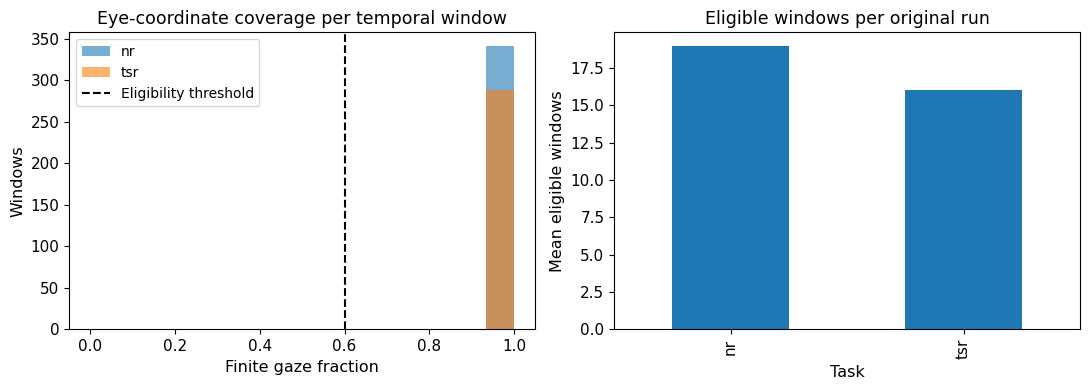

In [6]:
# ============ 05. Examine Eye Coverage and Source Event Alignment ============

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for task, part in registry.groupby('task'):
    axes[0].hist(part.eye_valid_fraction, bins=np.linspace(0, 1, 16),
                 alpha=0.6, label=task)
axes[0].axvline(min_eye_fraction, ls='--', color='black',
                label='Eligibility threshold')
axes[0].set(title='Eye-coordinate coverage per temporal window',
            xlabel='Finite gaze fraction', ylabel='Windows')
axes[0].legend()
report_table.groupby('task')[['eligible_windows']].mean().plot(
    kind='bar', ax=axes[1], legend=False)
axes[1].set(title='Eligible windows per original run',
            ylabel='Mean eligible windows', xlabel='Task')
fig.tight_layout()
fig.savefig(output_dir / '02_alignment_quality.png', dpi=170)
plt.show()


**06. Save the Window and Alignment Evidence**

Five outputs describe the paired-window dataset:

| Output | Recorded information |
| --- | --- |
| `02_window_registry.csv` | **630** unique 12-second windows and their source identities, timing, roles and eligibility |
| `02_alignment_quality.csv` | **36** run-level overlap, duration and timing records |
| `02_window_summary.csv` | **Six** partition/task window counts |
| `02_person_task_quality.csv` | **36** participant/task summaries, including finite-coordinate coverage |
| `02_alignment_quality.png` | Observed window eligibility and run support |

All **18 participants** and **36 original runs** are represented. These files define the exact windows subsequently used for EEG and gaze feature extraction; no new participant allocation is performed.

In [7]:
# ========== 06. Save Window Registry and Source Alignment Evidence ===========

registry.to_csv(output_dir / '02_window_registry.csv', index=False)
report_table.to_csv(output_dir / '02_alignment_quality.csv',
                    index=False)
summary = (registry.groupby(['split', 'task'])
           .agg(total=('window_id', 'size'),
                eligible=('eligible', 'sum'),
                people=('participant_id', 'nunique'))
           .reset_index())
summary.to_csv(output_dir / '02_window_summary.csv', index=False)
# One source-run/task quality row per person and task, not a window-level
# pseudo-replication. Each run contributes a separately reported denominator.
person_task_quality = (
    registry.groupby(['participant_id', 'split', 'task'])
    .agg(n_windows=('window_id', 'size'),
         n_eligible=('eligible', 'sum'),
         mean_finite_eye_fraction=('eye_valid_fraction', 'mean'),
         minimum_finite_eye_fraction=('eye_valid_fraction', 'min'))
    .reset_index())
person_task_quality.to_csv(
    output_dir / '02_person_task_quality.csv', index=False)
if (person_task_quality.groupby('participant_id').task.nunique().ne(2).any()
        or person_task_quality.n_eligible.eq(0).any()):
    raise ValueError('An included person has no eligible window for one task')
print('Independent people by split:',
      registry.groupby('split').participant_id.nunique().to_dict())
display(person_task_quality)
display(summary)
print("Window registry rows:", len(registry))
print("Unique source window IDs:", registry.window_id.nunique())
print("Distinct participant partitions:",
      registry.groupby("participant_id")["split"].nunique().max())
print("Saved stage-02 files:",
      ", ".join(sorted(p.name for p in output_dir.glob("02_*"))))


Independent people by split: {'test': 4, 'train': 11, 'validation': 3}


,participant_id,split,task,n_windows,n_eligible,mean_finite_eye_fraction,minimum_finite_eye_fraction
0,sub-YAC,test,nr,20,20,1.0,1.0
1,sub-YAC,test,tsr,20,20,1.0,1.0
2,sub-YAG,test,nr,20,20,1.0,1.0
3,sub-YAG,test,tsr,20,20,1.0,1.0
4,sub-YAK,train,nr,1,1,1.0,1.0
5,sub-YAK,train,tsr,20,20,1.0,1.0
6,sub-YDG,train,nr,20,20,1.0,1.0
7,sub-YDG,train,tsr,14,14,1.0,1.0
8,sub-YDR,validation,nr,20,20,1.0,1.0
9,sub-YDR,validation,tsr,11,11,1.0,1.0


,split,task,total,eligible,people
0,test,nr,80,80,4
1,test,tsr,80,80,4
2,train,nr,201,201,11
3,train,tsr,170,170,11
4,validation,nr,60,60,3
5,validation,tsr,39,39,3


Window registry rows: 630
Unique source window IDs: 630
Distinct participant partitions: 1
Saved stage-02 files: 02_alignment_quality.csv, 02_alignment_quality.png, 02_person_task_quality.csv, 02_window_registry.csv, 02_window_summary.csv


**07. Scientific Summary**

**630 paired windows from 18 participants** were retained, with original NR/TSR identities and participant-disjoint partitions preserved. Every run contributes data, but window support is unequal and gaze x/y availability is uniformly finite under the current criterion.

[Notebook 03](03_preprocessing_features_and_neurophysiology.ipynb) uses these windows to compute matched EEG and gaze features. The main interpretive distinction is between **shared BIDS-relative recording time** and **independently verified physiological synchronisation**: only the former is established here.

In [8]:
# ================== 07. Interpretation and Next Dependency ===================

print('Eligible windows:', int(eligible.shape[0]))
print('Independent people:', eligible.participant_id.nunique())
print('Independent drift checked:', False)
print('Next: 03_preprocessing_features_and_neurophysiology.ipynb')

download_outputs_from_colab("eeg_eye_tracking_fusion/output", "02")


Eligible windows: 630
Independent people: 18
Independent drift checked: False
Next: 03_preprocessing_features_and_neurophysiology.ipynb
------------------------------------------------------------------------
Notebook 02
Files packaged: 5
  + 02_alignment_quality.csv
  + 02_alignment_quality.png
  + 02_person_task_quality.csv
  + 02_window_registry.csv
  + 02_window_summary.csv
Download ZIP from Colab Contents: /content/eeg_eye_tracking_fusion_Notebook_02_Outputs.zip
